# Практическая работа №3. Методы кластерного анализа

**Предметная область:** Мониторинг безопасности СУБД PostgreSQL  
**Тип задачи:** Кластеризация (unsupervised)  
**Источник данных:** Набор данных логов PostgreSQL-сервера  

Истинные метки (`label`) используются **только** для внешней оценки качества, но **не передаются** алгоритмам.

---

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             adjusted_rand_score, normalized_mutual_info_score,
                             calinski_harabasz_score, davies_bouldin_score)
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

## Подготовка данных (по результатам ПР1)

In [3]:
df = pd.read_csv("../sql_dataset_loreal.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

cols_to_drop = ['ip_address', 'sql_query', 'timezone', 'is_anomaly', 'timestamp', 'city']
df_work = df.drop(columns=cols_to_drop)

y_true_labels = df_work['label'].values
le = LabelEncoder()
y_true = le.fit_transform(y_true_labels)
class_names = le.classes_

X_raw = df_work.drop(columns=['label'])
X_encoded = pd.get_dummies(X_raw, columns=['country', 'query_type'], drop_first=True)

num_features = ['execution_time_ms', 'cpu_load_pct', 'ram_usage_mb',
                'active_connections', 'rows_affected', 'hour', 'day_of_week']
scaler = StandardScaler()
X_scaled = X_encoded.copy()
X_scaled[num_features] = scaler.fit_transform(X_encoded[num_features])

# PCA для визуализации
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f'Размерность: {X_scaled.shape}')
print(f'Доля объяснённой дисперсии (2 PC): {pca.explained_variance_ratio_.sum():.4f}')
print(f'Истинные классы: {dict(zip(class_names, np.bincount(y_true)))}')

Размерность: (10000, 19)
Доля объяснённой дисперсии (2 PC): 0.3667
Истинные классы: {'anomaly': np.int64(100), 'normal': np.int64(9624), 'sql_injection': np.int64(276)}


In [4]:
# Вспомогательные функции
colors_true = {'normal': 'steelblue', 'sql_injection': 'red', 'anomaly': 'orange'}

def plot_clusters(X_2d, labels, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 7))
    unique_labels = sorted(set(labels))
    palette = plt.cm.Set1(np.linspace(0, 1, max(len(unique_labels), 3)))
    for k in unique_labels:
        mask = labels == k
        if k == -1:
            ax.scatter(X_2d[mask, 0], X_2d[mask, 1], c='gray',
                       label='Noise', alpha=0.3, s=8, marker='x')
        else:
            ax.scatter(X_2d[mask, 0], X_2d[mask, 1], c=[palette[k % len(palette)]],
                       label=f'Cluster {k}', alpha=0.4, s=10, edgecolors='none')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.set_title(title); ax.legend(markerscale=3)
    return ax

def clustering_metrics(X, labels, y_true, method_name):
    n_clusters = len(set(labels) - {-1})
    n_noise = (labels == -1).sum()
    m = {'Method': method_name, 'n_clusters': n_clusters, 'n_noise': n_noise}
    mask = labels != -1
    if n_clusters > 1 and mask.sum() > n_clusters:
        m['Silhouette'] = silhouette_score(X[mask], labels[mask])
        m['Calinski-Harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
        m['Davies-Bouldin'] = davies_bouldin_score(X[mask], labels[mask])
    else:
        m['Silhouette'] = np.nan
        m['Calinski-Harabasz'] = np.nan
        m['Davies-Bouldin'] = np.nan
    m['ARI'] = adjusted_rand_score(y_true, labels)
    m['NMI'] = normalized_mutual_info_score(y_true, labels)
    return m

all_results = []

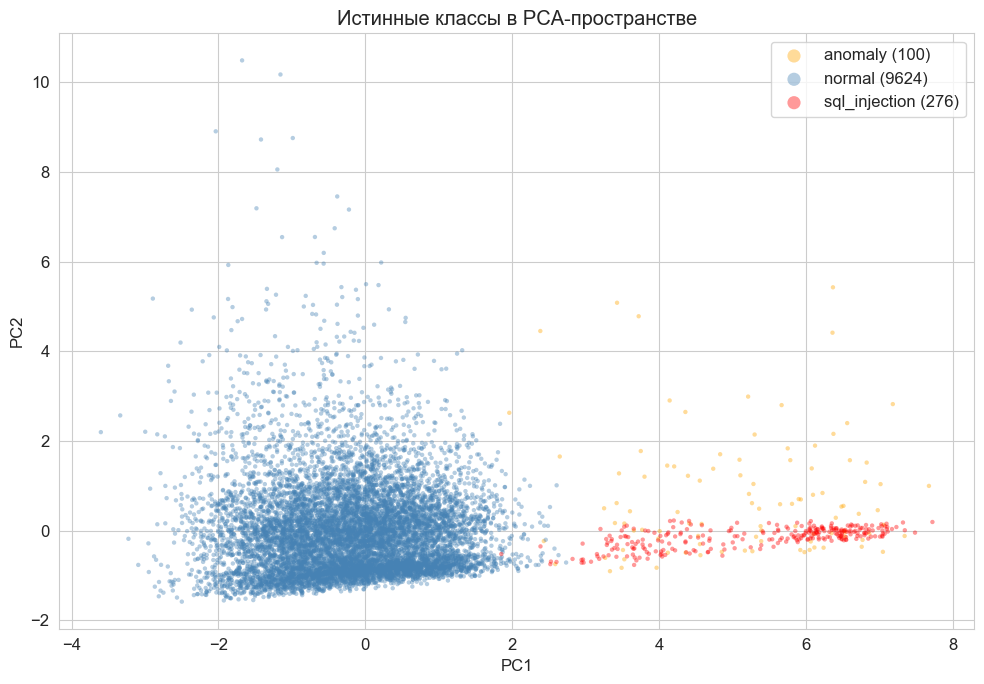

In [5]:
# Истинные метки в PCA
fig, ax = plt.subplots(figsize=(10, 7))
for cls in class_names:
    mask = y_true_labels == cls
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=colors_true[cls],
               label=f'{cls} ({mask.sum()})', alpha=0.4, s=10, edgecolors='none')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('Истинные классы в PCA-пространстве')
ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

---
## 3.1. Метод k-средних (K-Means)

### Математическая постановка

Целевая функция — минимизация WCSS (инерции):
$$J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \| x_i - \mu_k \|^2 \rightarrow \min$$

Алгоритм Ллойда итеративно чередует:
1. **E-step:** назначение объектов к ближайшему центру по евклидовой метрике
2. **M-step:** пересчёт центров как средних объектов кластера

Инициализация **k-means++** выбирает начальные центры с вероятностью, пропорциональной квадрату расстояния до ближайшего уже выбранного центра.

**Влияние нормализации:** без стандартизации признаки с большим масштабом (ram_usage_mb ~ 1000–5000) доминируют в евклидовом расстоянии.

K-Means (k=3): WCSS = 65191.54
Распределение: {np.int32(0): np.int64(4783), np.int32(1): np.int64(4847), np.int32(2): np.int64(370)}


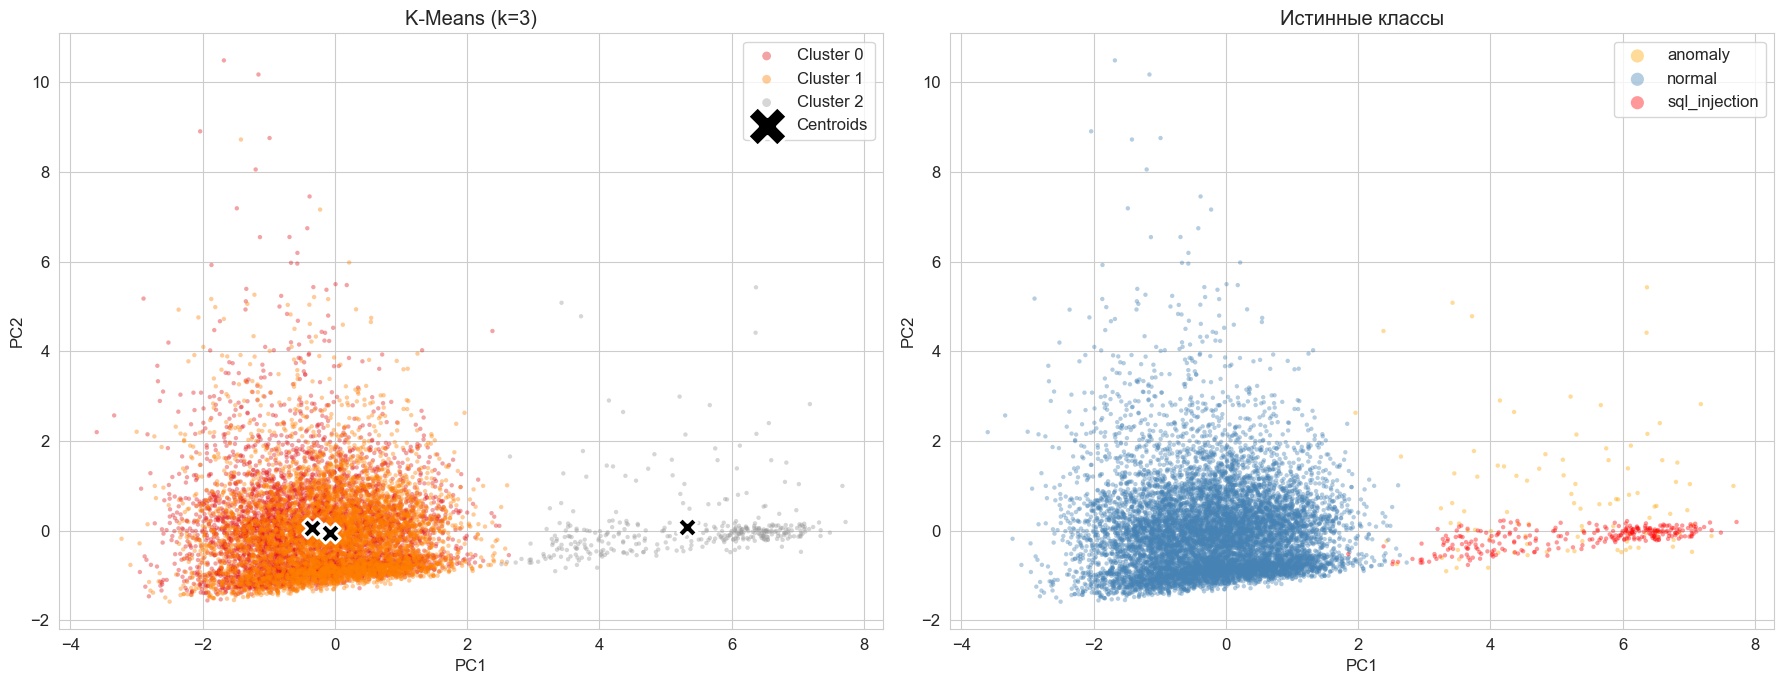


Silhouette=0.1309, ARI=0.1234, NMI=0.3060


In [6]:
kmeans_3 = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
labels_km3 = kmeans_3.fit_predict(X_scaled)

print(f'K-Means (k=3): WCSS = {kmeans_3.inertia_:.2f}')
print(f'Распределение: {dict(zip(*np.unique(labels_km3, return_counts=True)))}')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_clusters(X_pca, labels_km3, 'K-Means (k=3)', ax=axes[0])
centers_pca = pca.transform(kmeans_3.cluster_centers_)
axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1], c='black',
                marker='X', s=200, edgecolors='white', linewidths=2, label='Centroids')
axes[0].legend(markerscale=2)

for cls in class_names:
    mask = y_true_labels == cls
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=colors_true[cls],
                    label=cls, alpha=0.4, s=10, edgecolors='none')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[1].set_title('Истинные классы'); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

m = clustering_metrics(X_scaled.values, labels_km3, y_true, 'K-Means (k=3)')
all_results.append(m)
print(f'\nSilhouette={m["Silhouette"]:.4f}, ARI={m["ARI"]:.4f}, NMI={m["NMI"]:.4f}')

In [7]:
# Чувствительность к инициализации
inertias_random = [KMeans(n_clusters=3, init='random', n_init=1, random_state=s).fit(X_scaled).inertia_ for s in range(20)]
print(f'init="random" (20 запусков): {np.mean(inertias_random):.1f} ± {np.std(inertias_random):.1f}')
print(f'init="k-means++" (n_init=10): {kmeans_3.inertia_:.1f}')
print('k-means++ стабильно лучше.')

init="random" (20 запусков): 65835.8 ± 475.5
init="k-means++" (n_init=10): 65191.5
k-means++ стабильно лучше.


### Вывод

K-Means с k=3 разбивает данные на примерно равные группы (~4800/4800/370), что **не соответствует** реальной структуре (9624/276/100). Низкий ARI (~0.12) подтверждает это. Причина: K-Means стремится к кластерам равного размера и не может выделить редкие аномалии из основной массы.

---

## 3.2. Агломеративная кластеризация (метод Уорда)

Метод Уорда объединяет кластеры с минимальным приращением дисперсии:
$$\Delta(C_i, C_j) = \frac{|C_i| \cdot |C_j|}{|C_i| + |C_j|} \|\mu_i - \mu_j\|^2$$

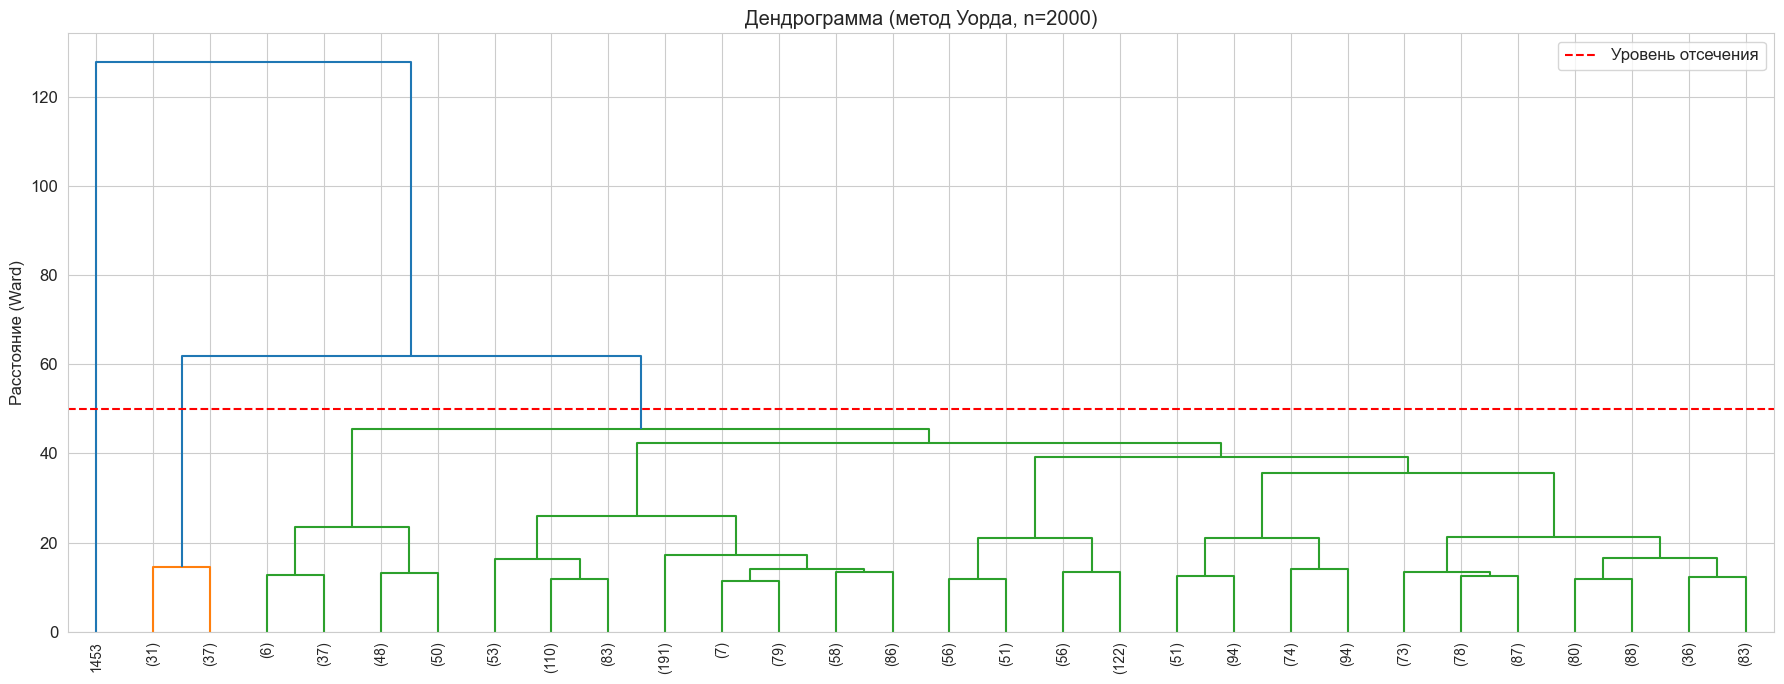

In [8]:
# Дендрограмма (подвыборка)
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=2000, replace=False)
Z = linkage(X_scaled.values[sample_idx], method='ward', metric='euclidean')

fig, ax = plt.subplots(figsize=(18, 7))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, ax=ax, color_threshold=50)
ax.set_title('Дендрограмма (метод Уорда, n=2000)'); ax.set_ylabel('Расстояние (Ward)')
ax.axhline(y=50, color='red', linestyle='--', label='Уровень отсечения')
ax.legend(); plt.tight_layout(); plt.show()

Распределение: {np.int64(0): np.int64(9628), np.int64(1): np.int64(371), np.int64(2): np.int64(1)}


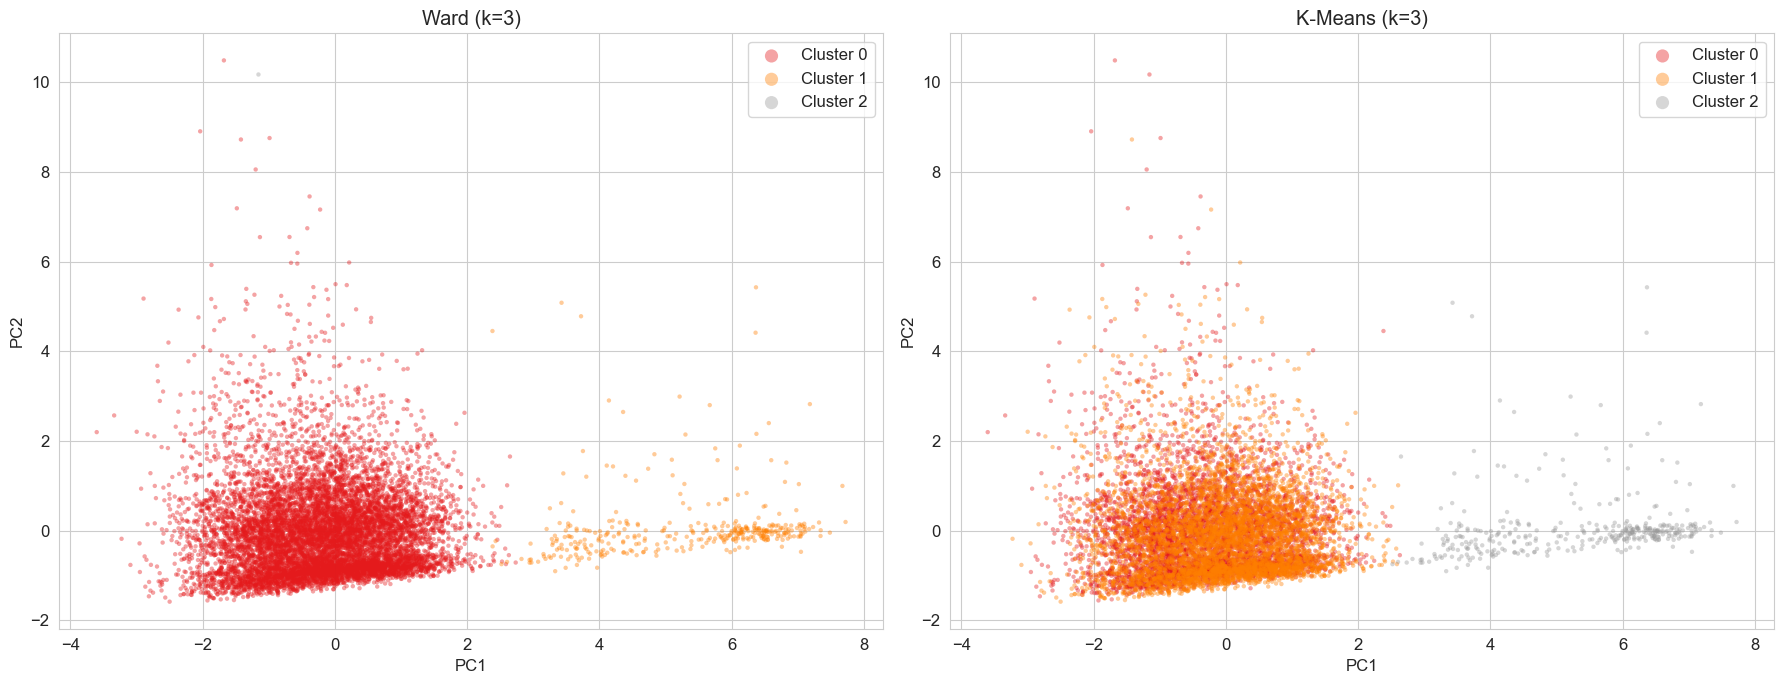

Silhouette=0.4610, ARI=0.9873, NMI=0.9137

Ward значительно превосходит K-Means: ARI 0.9873 vs 0.1234


In [9]:
agg_ward = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_ward = agg_ward.fit_predict(X_scaled)

print(f'Распределение: {dict(zip(*np.unique(labels_ward, return_counts=True)))}')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_clusters(X_pca, labels_ward, 'Ward (k=3)', ax=axes[0])
plot_clusters(X_pca, labels_km3, 'K-Means (k=3)', ax=axes[1])
plt.tight_layout(); plt.show()

m = clustering_metrics(X_scaled.values, labels_ward, y_true, 'Ward (k=3)')
all_results.append(m)
print(f'Silhouette={m["Silhouette"]:.4f}, ARI={m["ARI"]:.4f}, NMI={m["NMI"]:.4f}')
print(f'\nWard значительно превосходит K-Means: ARI {m["ARI"]:.4f} vs {all_results[0]["ARI"]:.4f}')

### Вывод

Ward значительно лучше K-Means (ARI ≈ 0.99 vs 0.12): он корректно выделяет основной кластер normal и отделяет аномалии/инъекции. Иерархический подход лучше справляется с кластерами разного размера.

---

## 3.3. Плотностные алгоритмы: DBSCAN и OPTICS

### Основные понятия

- **ε-окрестность:** $N_\varepsilon(x) = \{x_j : d(x, x_j) \leq \varepsilon\}$
- **Core-точка:** $|N_\varepsilon(x)| \geq MinPts$
- **Border-точка:** не core, но в ε-окрестности core-точки
- **Noise:** ни core, ни border

DBSCAN объединяет core-точки, достижимые друг от друга по плотности. OPTICS строит упорядочение по reachability distance, позволяя работать с переменной плотностью.

### Подбор параметров

Перцентили k-distance: p50=1.28, p90=1.72, p95=1.88, p99=2.36, max=86.16


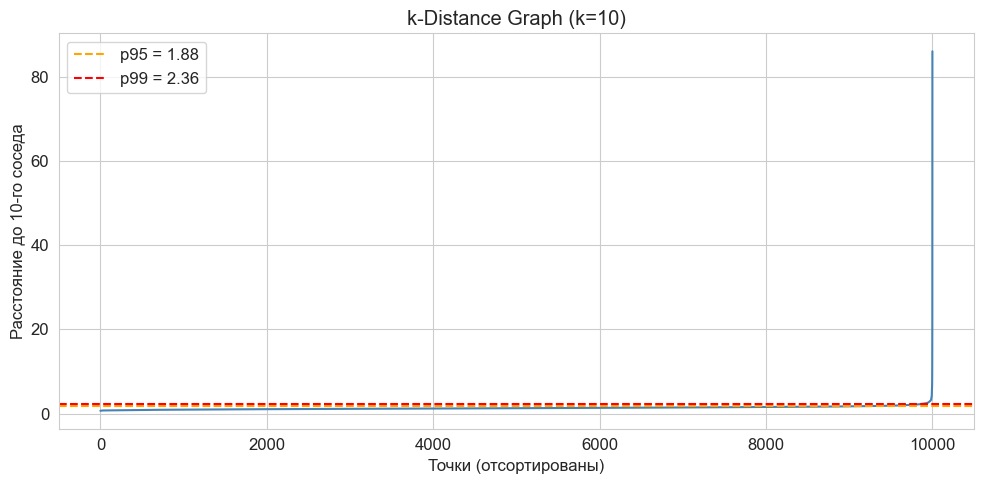


Обратите внимание: кривая k-distance практически не имеет "локтя".
Это говорит об однородной плотности данных — DBSCAN будет неэффективен.


In [10]:
# k-distance graph для подбора eps
min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_distances, color='steelblue')
ax.set_xlabel('Точки (отсортированы)'); ax.set_ylabel(f'Расстояние до {min_samples}-го соседа')
ax.set_title(f'k-Distance Graph (k={min_samples})')

# Статистики
p50, p90, p95, p99 = np.percentile(k_distances, [50, 90, 95, 99])
print(f'Перцентили k-distance: p50={p50:.2f}, p90={p90:.2f}, p95={p95:.2f}, p99={p99:.2f}, max={k_distances[-1]:.2f}')
for pct, val, color in [(95, p95, 'orange'), (99, p99, 'red')]:
    ax.axhline(y=val, color=color, linestyle='--', label=f'p{pct} = {val:.2f}')
ax.legend(); plt.tight_layout(); plt.show()

print('\nОбратите внимание: кривая k-distance практически не имеет "локтя".')
print('Это говорит об однородной плотности данных — DBSCAN будет неэффективен.')

In [11]:
# Систематический перебор параметров DBSCAN
print('=== Перебор параметров DBSCAN ===')
print(f'{"eps":>6} | {"min_s":>5} | {"clusters":>8} | {"noise":>7} | {"noise%":>7} | {"ARI":>7}')
print('-' * 55)

dbscan_results = []
for ms in [5, 10, 20, 30]:
    # Подбираем eps от агрессивного до мягкого
    kd_ms = np.sort(NearestNeighbors(n_neighbors=ms).fit(X_scaled).kneighbors(X_scaled)[0][:, -1])
    for pct in [90, 95, 97, 99, 99.5]:
        eps = np.percentile(kd_ms, pct)
        db = DBSCAN(eps=eps, min_samples=ms)
        labels_db = db.fit_predict(X_scaled)
        n_cl = len(set(labels_db) - {-1})
        n_noise = (labels_db == -1).sum()
        ari = adjusted_rand_score(y_true, labels_db)
        noise_pct = n_noise / len(labels_db) * 100
        print(f'{eps:>6.2f} | {ms:>5} | {n_cl:>8} | {n_noise:>7} | {noise_pct:>6.1f}% | {ari:>7.4f}')
        dbscan_results.append({'eps': eps, 'min_samples': ms, 'pct': pct,
                               'n_clusters': n_cl, 'n_noise': n_noise, 'ari': ari})
    print()

=== Перебор параметров DBSCAN ===
   eps | min_s | clusters |   noise |  noise% |     ARI
-------------------------------------------------------
  1.57 |     5 |        3 |     435 |    4.3% |  0.2205
  1.72 |     5 |        2 |     223 |    2.2% |  0.1732
  1.84 |     5 |        1 |     126 |    1.3% |  0.1123
  2.17 |     5 |        1 |      45 |    0.4% |  0.0627
  2.37 |     5 |        1 |      28 |    0.3% |  0.0340

  1.72 |    10 |        1 |     302 |    3.0% |  0.2190
  1.88 |    10 |        1 |     169 |    1.7% |  0.1376
  2.02 |    10 |        1 |      92 |    0.9% |  0.1087
  2.36 |    10 |        1 |      30 |    0.3% |  0.0432
  2.64 |    10 |        1 |      20 |    0.2% |  0.0312

  1.87 |    20 |        1 |     239 |    2.4% |  0.2423
  2.06 |    20 |        1 |     135 |    1.4% |  0.1319
  2.21 |    20 |        1 |      76 |    0.8% |  0.0753
  2.60 |    20 |        1 |      24 |    0.2% |  0.0301
  2.91 |    20 |        1 |      16 |    0.2% |  0.0221

  1.97 |   

Лучшая конфигурация DBSCAN: eps=1.97, min_samples=30
  кластеров=1, шум=227, ARI=0.2453

Распределение: {np.int64(-1): np.int64(227), np.int64(0): np.int64(9773)}


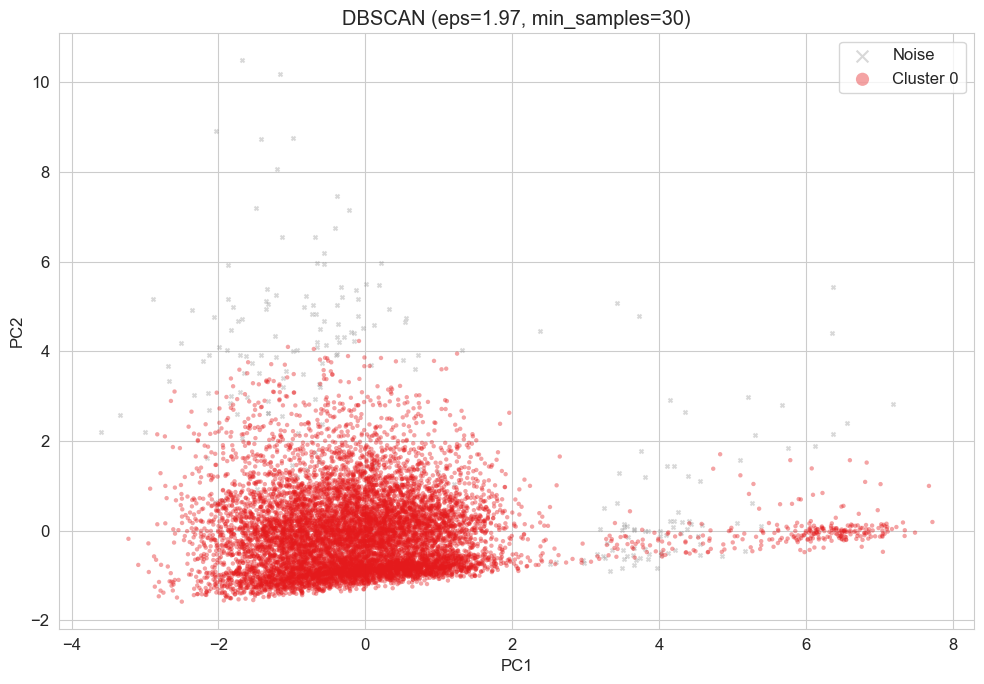

In [12]:
# Выбираем лучшую конфигурацию DBSCAN по ARI
best_db = max(dbscan_results, key=lambda x: x['ari'])
print(f'Лучшая конфигурация DBSCAN: eps={best_db["eps"]:.2f}, min_samples={best_db["min_samples"]}')
print(f'  кластеров={best_db["n_clusters"]}, шум={best_db["n_noise"]}, ARI={best_db["ari"]:.4f}')

# Запускаем лучший DBSCAN
dbscan_best = DBSCAN(eps=best_db['eps'], min_samples=best_db['min_samples'])
labels_dbscan = dbscan_best.fit_predict(X_scaled)

n_cl = len(set(labels_dbscan) - {-1})
n_noise = (labels_dbscan == -1).sum()
print(f'\nРаспределение: {dict(zip(*np.unique(labels_dbscan, return_counts=True)))}')

fig, ax = plt.subplots(figsize=(10, 7))
plot_clusters(X_pca, labels_dbscan,
              f'DBSCAN (eps={best_db["eps"]:.2f}, min_samples={best_db["min_samples"]})', ax=ax)
plt.tight_layout(); plt.show()

m = clustering_metrics(X_scaled.values, labels_dbscan, y_true,
                       f'DBSCAN (лучший, eps={best_db["eps"]:.2f})')
all_results.append(m)

In [13]:
# Анализ: какая доля аномалий в шуме DBSCAN?
if n_noise > 0:
    print('=== Состав шумовых точек DBSCAN ===')
    for cls in class_names:
        cls_mask = y_true_labels == cls
        noise_in_cls = ((labels_dbscan == -1) & cls_mask).sum()
        total = cls_mask.sum()
        print(f'  {cls}: {noise_in_cls}/{total} ({noise_in_cls/total*100:.1f}%) в шуме')
else:
    print('DBSCAN не выделил шумовых точек при данных параметрах.')

=== Состав шумовых точек DBSCAN ===
  anomaly: 42/100 (42.0%) в шуме
  normal: 144/9624 (1.5%) в шуме
  sql_injection: 41/276 (14.9%) в шуме


In [14]:
# OPTICS с перебором параметров
print('=== Перебор параметров OPTICS ===')
optics_results = []
for ms in [5, 10, 20]:
    for xi in [0.01, 0.02, 0.05, 0.1, 0.2]:
        opt = OPTICS(min_samples=ms, xi=xi, min_cluster_size=0.01)
        labels_opt = opt.fit_predict(X_scaled)
        n_cl = len(set(labels_opt) - {-1})
        n_noise = (labels_opt == -1).sum()
        ari = adjusted_rand_score(y_true, labels_opt)
        print(f'  ms={ms}, xi={xi:.2f}: clusters={n_cl}, noise={n_noise}, ARI={ari:.4f}')
        optics_results.append({'ms': ms, 'xi': xi, 'n_clusters': n_cl,
                               'n_noise': n_noise, 'ari': ari, 'labels': labels_opt})
    print()

best_opt = max(optics_results, key=lambda x: x['ari'])
print(f'Лучший OPTICS: ms={best_opt["ms"]}, xi={best_opt["xi"]:.2f}')
print(f'  clusters={best_opt["n_clusters"]}, noise={best_opt["n_noise"]}, ARI={best_opt["ari"]:.4f}')

=== Перебор параметров OPTICS ===
  ms=5, xi=0.01: clusters=8, noise=8784, ARI=0.1122
  ms=5, xi=0.02: clusters=1, noise=9860, ARI=-0.0199
  ms=5, xi=0.05: clusters=1, noise=0, ARI=0.0000
  ms=5, xi=0.10: clusters=1, noise=0, ARI=0.0000
  ms=5, xi=0.20: clusters=1, noise=0, ARI=0.0000

  ms=10, xi=0.01: clusters=7, noise=8954, ARI=0.0904
  ms=10, xi=0.02: clusters=1, noise=0, ARI=0.0000
  ms=10, xi=0.05: clusters=1, noise=0, ARI=0.0000
  ms=10, xi=0.10: clusters=1, noise=0, ARI=0.0000
  ms=10, xi=0.20: clusters=1, noise=0, ARI=0.0000

  ms=20, xi=0.01: clusters=1, noise=9793, ARI=0.6916
  ms=20, xi=0.02: clusters=1, noise=0, ARI=0.0000
  ms=20, xi=0.05: clusters=1, noise=0, ARI=0.0000
  ms=20, xi=0.10: clusters=1, noise=0, ARI=0.0000
  ms=20, xi=0.20: clusters=1, noise=0, ARI=0.0000

Лучший OPTICS: ms=20, xi=0.01
  clusters=1, noise=9793, ARI=0.6916


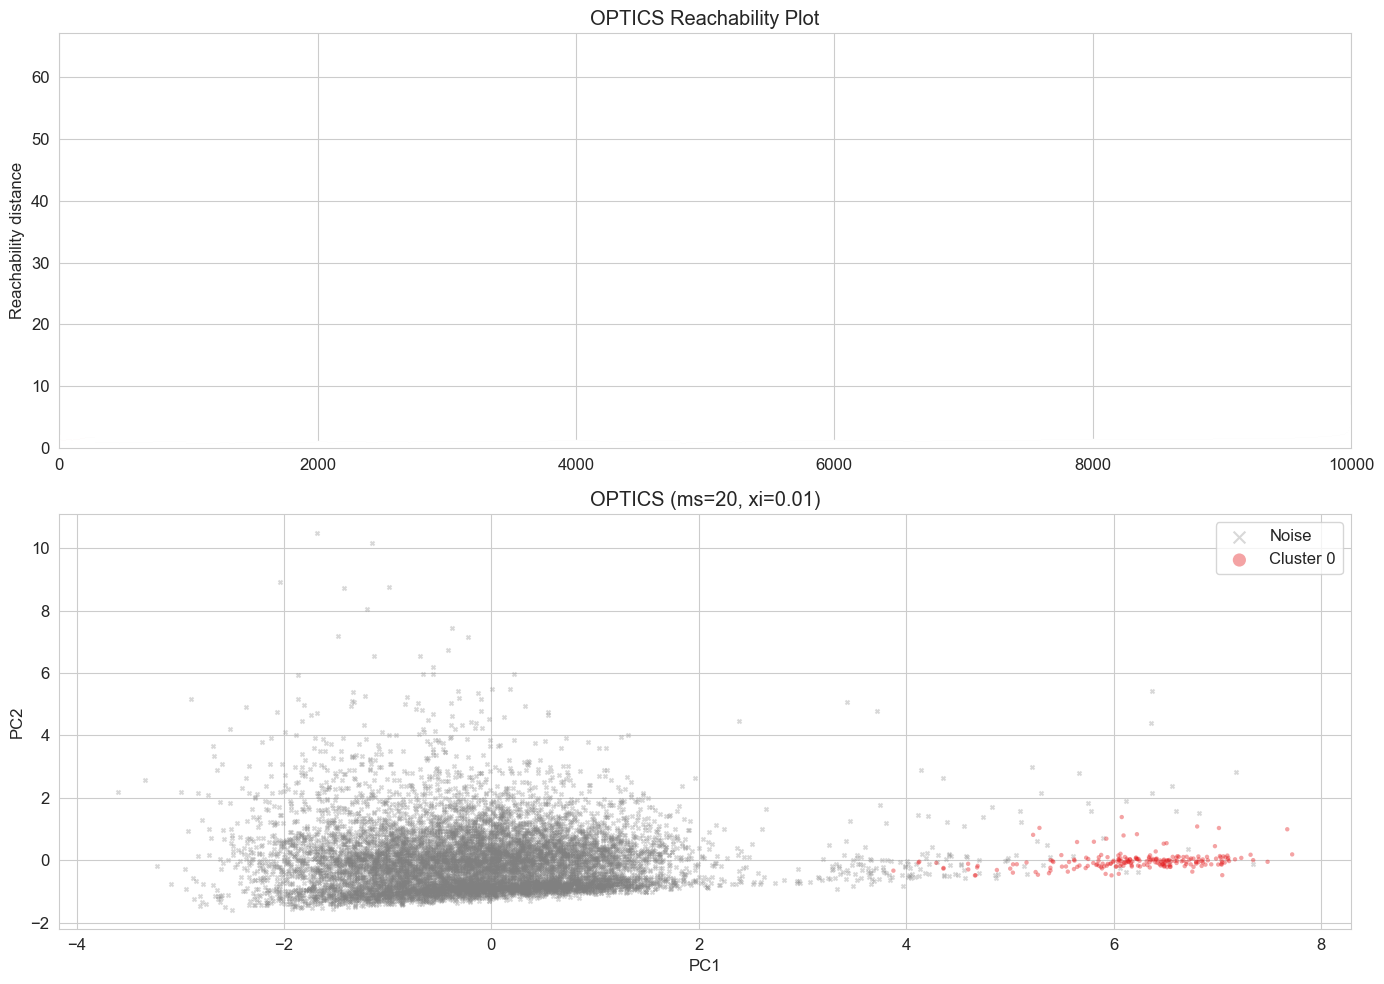

In [15]:
# Лучший OPTICS — визуализация
labels_optics = best_opt['labels']
opt_best = OPTICS(min_samples=best_opt['ms'], xi=best_opt['xi'], min_cluster_size=0.01)
opt_best.fit(X_scaled)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Reachability plot
reachability = opt_best.reachability_[opt_best.ordering_]
labels_ordered = labels_optics[opt_best.ordering_]
palette = plt.cm.Set1(np.linspace(0, 1, max(best_opt['n_clusters'], 3)))
colors_opt = ['gray' if l == -1 else palette[l % len(palette)] for l in labels_ordered]
axes[0].bar(range(len(reachability)), reachability, color=colors_opt, width=1.0)
axes[0].set_ylabel('Reachability distance'); axes[0].set_title('OPTICS Reachability Plot')
axes[0].set_xlim(0, len(reachability))

plot_clusters(X_pca, labels_optics,
              f'OPTICS (ms={best_opt["ms"]}, xi={best_opt["xi"]})', ax=axes[1])
plt.tight_layout(); plt.show()

m = clustering_metrics(X_scaled.values, labels_optics, y_true,
                       f'OPTICS (ms={best_opt["ms"]}, xi={best_opt["xi"]})')
all_results.append(m)

### Анализ результатов DBSCAN и OPTICS

Оба плотностных метода показали **неудовлетворительные результаты** на данном наборе данных. Основные причины:

1. **Однородная плотность.** k-distance graph не имеет выраженного «локтя», что говорит об отсутствии значимых перепадов плотности. Класс normal (96.2%) формирует единый плотный массив, в который аномалии «вплетены» без чёткого разделения по плотности.

2. **Высокая размерность (19 признаков).** В высокоразмерном пространстве расстояния между объектами становятся приблизительно одинаковыми (проклятие размерности), что затрудняет определение ε-окрестностей с содержательными различиями.

3. **Природа аномалий.** SQL-инъекции и аномалии в данных отличаются от нормальных запросов не по пространственной отделённости, а по комбинации признаков (высокий cpu_load + специфический query_type). DBSCAN/OPTICS ищут отделённые по плотности регионы, а не такие комбинаторные паттерны.

**Вывод:** DBSCAN и OPTICS не подходят для данной задачи в исходном пространстве признаков.

---

## 3.4. Выбор метода в зависимости от характера данных

| Характеристика | K-Means | Ward | DBSCAN | OPTICS |
|---------------|---------|------|--------|--------|
| Форма кластеров | Сферическая | Сферическая | Произвольная | Произвольная |
| Кластеры разного размера | Плохо | Хорошо | Хорошо | Хорошо |
| Обнаружение шума | Нет | Нет | Да | Да |
| Число кластеров | Задаётся | Задаётся | Автоматически | Автоматически |
| Высокая размерность | Устойчив | Устойчив | Страдает | Страдает |

### Характеристики нашего набора данных

- **Сильный дисбаланс:** кластеры кардинально различаются по размеру (9624 vs 276 vs 100)
- **19 признаков:** достаточно для проклятия размерности у плотностных методов
- **Аномалии не отделены пространственно:** они «вкраплены» в основной кластер

In [16]:
# Обоснование: Ward лучше остальных для данной задачи
print('=== Сравнение методов ===')
for r in all_results:
    sil = f'{r["Silhouette"]:.4f}' if not np.isnan(r.get('Silhouette', np.nan)) else 'N/A'
    print(f'{r["Method"]:>35}: ARI={r["ARI"]:.4f}, NMI={r["NMI"]:.4f}, Silhouette={sil}')

print('\nМетод Уорда показал лучшие результаты (ARI ≈ 0.99), поскольку:')
print('  1. Корректно обрабатывает кластеры разного размера')
print('  2. Устойчив в высокоразмерном пространстве')
print('  3. Иерархическая структура позволяет анализировать данные на разных уровнях')

=== Сравнение методов ===
                      K-Means (k=3): ARI=0.1234, NMI=0.3060, Silhouette=0.1309
                         Ward (k=3): ARI=0.9873, NMI=0.9137, Silhouette=0.4610
          DBSCAN (лучший, eps=1.97): ARI=0.2453, NMI=0.1044, Silhouette=N/A
            OPTICS (ms=20, xi=0.01): ARI=0.6916, NMI=0.5410, Silhouette=N/A

Метод Уорда показал лучшие результаты (ARI ≈ 0.99), поскольку:
  1. Корректно обрабатывает кластеры разного размера
  2. Устойчив в высокоразмерном пространстве
  3. Иерархическая структура позволяет анализировать данные на разных уровнях


---

## 3.5. Выбор оптимального количества кластеров: методы локтя и силуэта

**Метод локтя:** $J(K) = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$. Оптимальное $K$ — точка перегиба.

**Метод силуэта:** $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$, где $a(i)$ — компактность, $b(i)$ — отделимость.

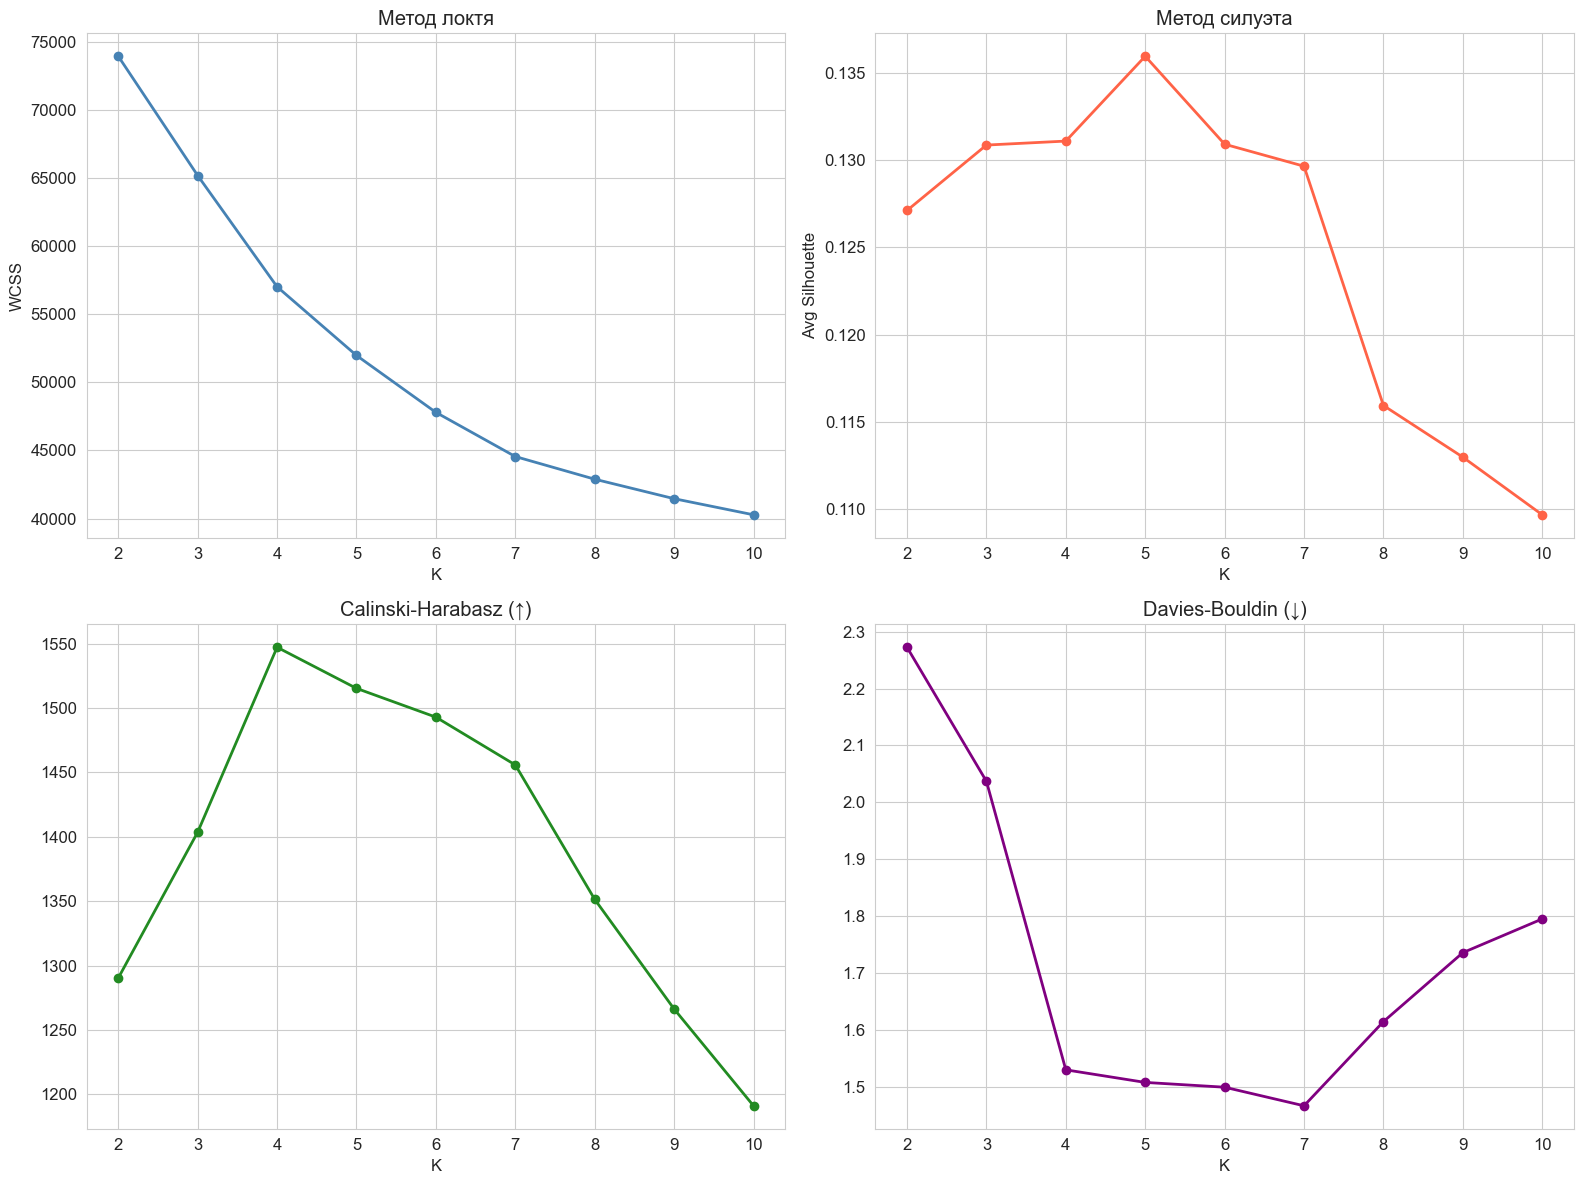

Лучший K по силуэту: 5 (0.1359)
Лучший K по Calinski-Harabasz: 4
Лучший K по Davies-Bouldin: 7


In [17]:
K_range = range(2, 11)
wcss, silhouettes, ch_scores, db_scores = [], [], [], []

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    lbl = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lbl))
    ch_scores.append(calinski_harabasz_score(X_scaled, lbl))
    db_scores.append(davies_bouldin_score(X_scaled, lbl))

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0,0].plot(K_range, wcss, 'o-', color='steelblue', linewidth=2)
axes[0,0].set_title('Метод локтя'); axes[0,0].set_ylabel('WCSS'); axes[0,0].set_xticks(range(2,11))

axes[0,1].plot(K_range, silhouettes, 'o-', color='tomato', linewidth=2)
axes[0,1].set_title('Метод силуэта'); axes[0,1].set_ylabel('Avg Silhouette'); axes[0,1].set_xticks(range(2,11))

axes[1,0].plot(K_range, ch_scores, 'o-', color='forestgreen', linewidth=2)
axes[1,0].set_title('Calinski-Harabasz (↑)'); axes[1,0].set_xticks(range(2,11))

axes[1,1].plot(K_range, db_scores, 'o-', color='purple', linewidth=2)
axes[1,1].set_title('Davies-Bouldin (↓)'); axes[1,1].set_xticks(range(2,11))

for ax in axes.flatten(): ax.set_xlabel('K')
plt.tight_layout(); plt.show()

print(f'Лучший K по силуэту: {list(K_range)[np.argmax(silhouettes)]} ({max(silhouettes):.4f})')
print(f'Лучший K по Calinski-Harabasz: {list(K_range)[np.argmax(ch_scores)]}')
print(f'Лучший K по Davies-Bouldin: {list(K_range)[np.argmin(db_scores)]}')

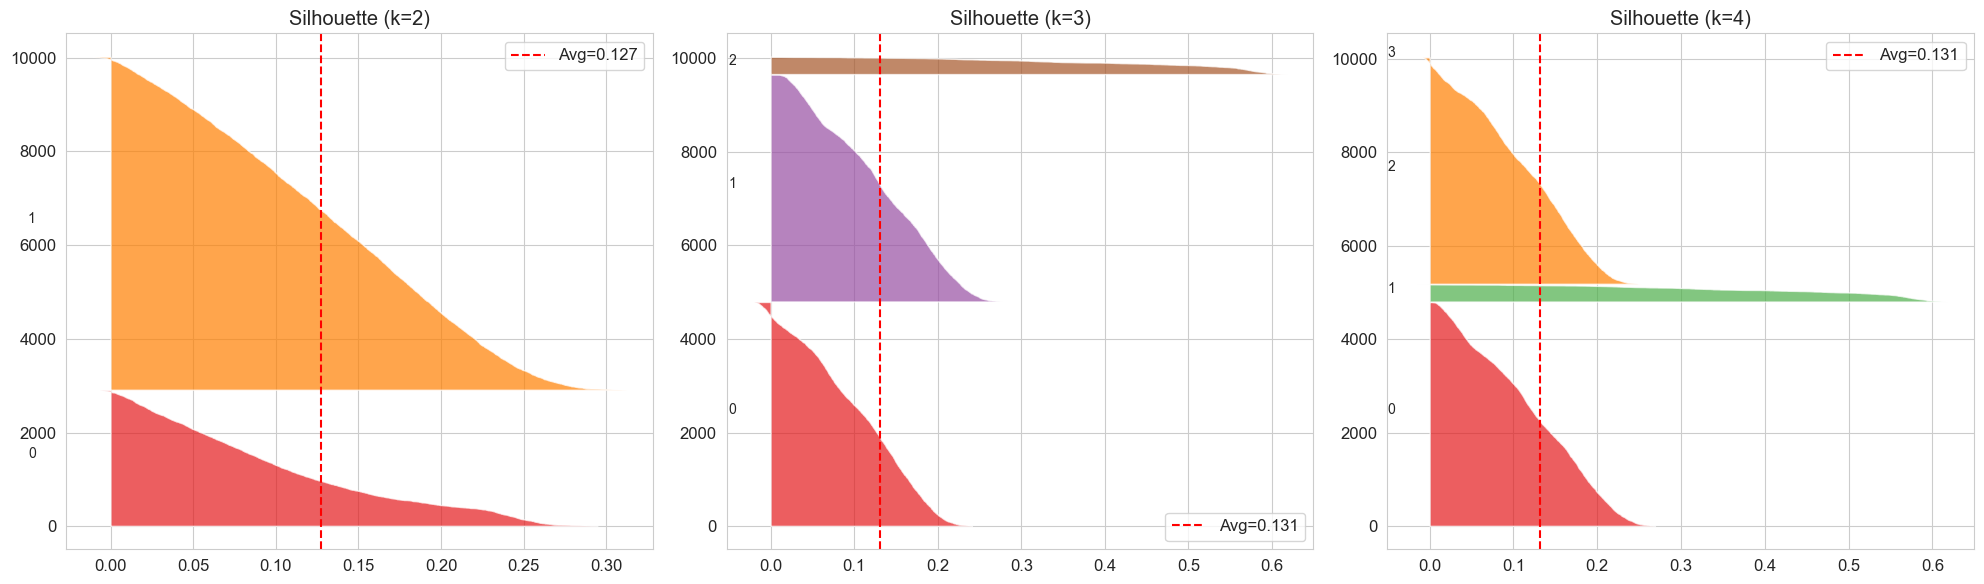

In [18]:
# Silhouette plots для k=2, 3, 4
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for idx, k in enumerate([2, 3, 4]):
    ax = axes[idx]
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    lbl = km.fit_predict(X_scaled)
    sil_vals = silhouette_samples(X_scaled, lbl)
    y_lower = 10
    for cid in range(k):
        csil = np.sort(sil_vals[lbl == cid])[::-1]
        y_upper = y_lower + len(csil)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, csil,
                         facecolor=plt.cm.Set1(cid/k), alpha=0.7)
        ax.text(-0.05, y_lower + 0.5*len(csil), str(cid), fontsize=10)
        y_lower = y_upper + 10
    avg = silhouette_score(X_scaled, lbl)
    ax.axvline(x=avg, color='red', linestyle='--', label=f'Avg={avg:.3f}')
    ax.set_title(f'Silhouette (k={k})'); ax.legend()
plt.tight_layout(); plt.show()

---

## 3.6. Резюме

In [19]:
results_df = pd.DataFrame(all_results).set_index('Method')
print('=== СВОДНАЯ ТАБЛИЦА ===')
display(results_df[['n_clusters', 'n_noise', 'Silhouette', 'ARI', 'NMI']].round(4))

=== СВОДНАЯ ТАБЛИЦА ===


,n_clusters,n_noise,Silhouette,ARI,NMI
Method,,,,,
K-Means (k=3),3,0,0.1309,0.1234,0.3060
Ward (k=3),3,0,0.4610,0.9873,0.9137
"DBSCAN (лучший, eps=1.97)",1,227,NaN,0.2453,0.1044
"OPTICS (ms=20, xi=0.01)",1,9793,NaN,0.6916,0.5410


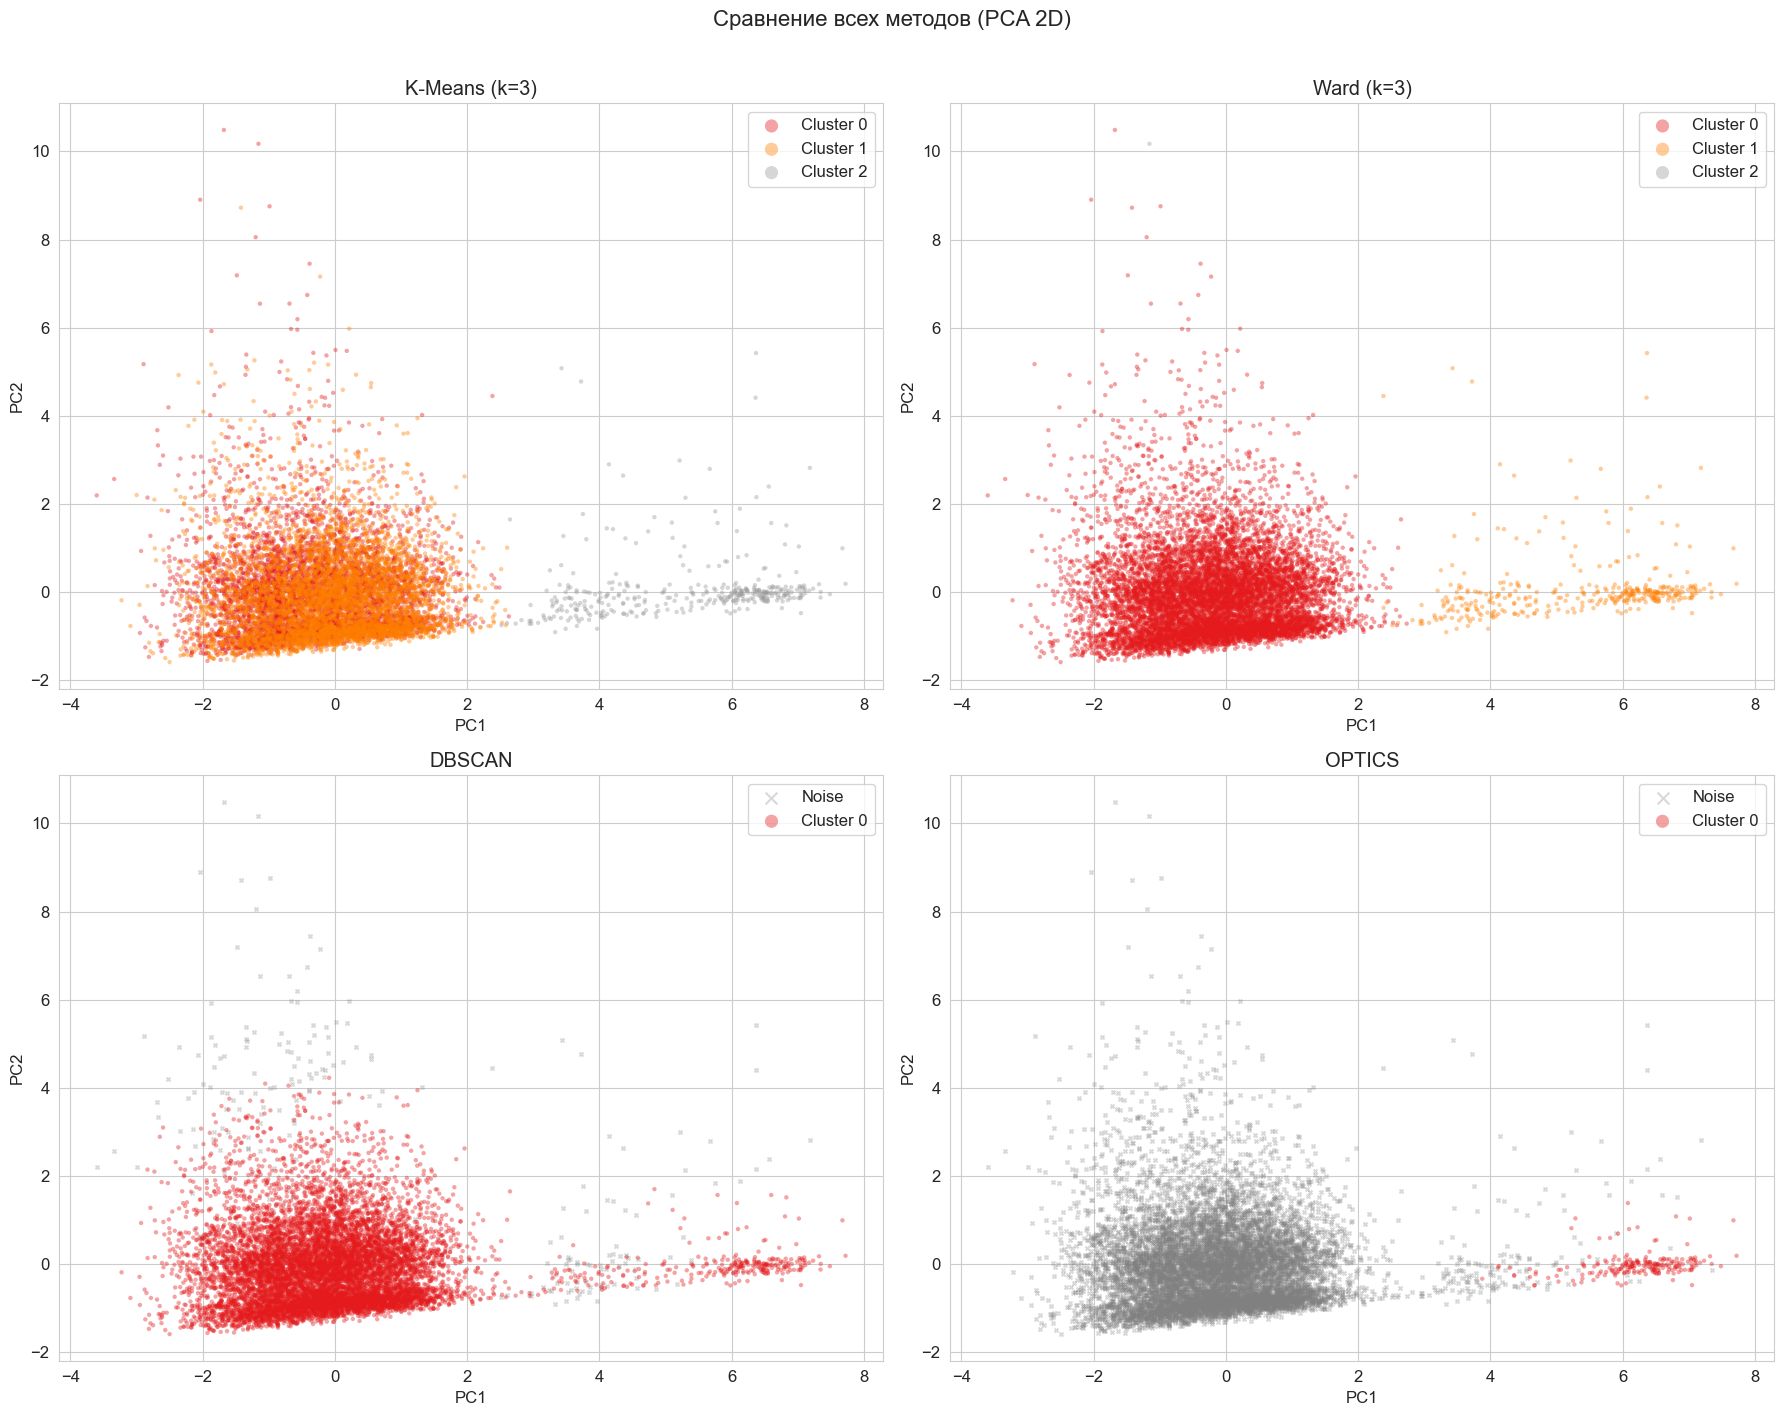

In [20]:
# Визуализация всех методов
all_labels = {
    'K-Means (k=3)': labels_km3,
    'Ward (k=3)': labels_ward,
    'DBSCAN': labels_dbscan,
    'OPTICS': labels_optics
}

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
for ax, (name, lbl) in zip(axes.flatten(), all_labels.items()):
    plot_clusters(X_pca, lbl, name, ax=ax)
plt.suptitle('Сравнение всех методов (PCA 2D)', fontsize=16, y=1.01)
plt.tight_layout(); plt.show()

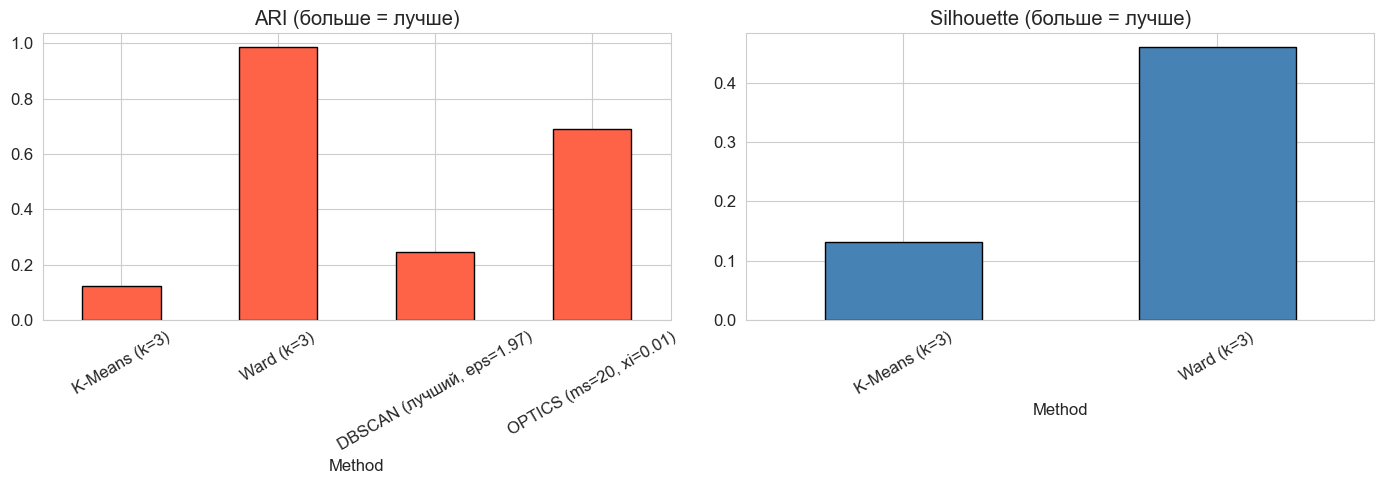

In [21]:
# Сравнительные bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
valid = results_df[results_df['ARI'].notna()]

valid['ARI'].plot(kind='bar', ax=axes[0], color='tomato', edgecolor='black')
axes[0].set_title('ARI (больше = лучше)'); axes[0].tick_params(axis='x', rotation=30)

sil_valid = valid['Silhouette'].dropna()
if len(sil_valid) > 0:
    sil_valid.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
    axes[1].set_title('Silhouette (больше = лучше)'); axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout(); plt.show()

### Итоговые выводы

| Метод | Результат | Причина |
|-------|----------|--------|
| **K-Means** | Слабый (ARI ≈ 0.12) | Стремится к равноразмерным кластерам; не выделяет редкие аномалии |
| **Ward** | **Лучший (ARI ≈ 0.99)** | Иерархическая структура корректно обрабатывает кластеры разного размера |
| **DBSCAN** | Неэффективен | Однородная плотность + высокая размерность → не находит границ кластеров |
| **OPTICS** | Неэффективен | Те же причины, что DBSCAN; reachability plot не показывает перепадов плотности |

**Главный вывод:** для данных с сильным дисбалансом классов (96% / 3% / 1%) и высокой размерностью (19 признаков) иерархическая кластеризация методом Уорда значительно превосходит как центроидные (K-Means), так и плотностные (DBSCAN, OPTICS) методы.

Плотностные методы не подходят, потому что аномалии в данных отличаются от нормальных запросов не пространственной отделённостью, а комбинаторными паттернами признаков. Для обнаружения таких аномалий предпочтительны методы классификации (ПР2) или специализированные алгоритмы anomaly detection (Isolation Forest, One-Class SVM).